<a href="https://colab.research.google.com/github/AmarSai01/nvidia-gpu-ml-jax-labs/blob/main/03_JAX_GPU_Labs_Shakespeare_Transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi -L
import jax
print("JAX version:", jax.__version__)
print("Devices:", jax.devices())

GPU 0: Tesla T4 (UUID: GPU-289413ef-161e-df0a-7699-729f389faedc)
JAX version: 0.11.1
Devices: [CudaDevice(id=0)]


In [ ]:
import jax.numpy as jnp, numpy as np, time

x = jnp.arange(10.0)
print(x, "lives on:", x.devices())

a = np.random.rand(4000, 4000).astype(np.float32)
s = time.time(); np.dot(a, a); cpu = time.time() - s

ag = jnp.asarray(a)
jnp.dot(ag, ag).block_until_ready()          # warm-up
s = time.time(); jnp.dot(ag, ag).block_until_ready(); gpu = time.time() - s
print(f"CPU {cpu:.3f}s | GPU {gpu:.4f}s -> {cpu/gpu:.0f}x faster")

[0. 1. 2. 3. 4. 5. 6. 7. 8. 9.] lives on: {CudaDevice(id=0)}
CPU 1.118s | GPU 0.0276s -> 40x faster


In [ ]:
from jax import jit, grad, vmap

def selu(x, alpha=1.67, lam=1.05):
    return lam * jnp.where(x > 0, x, alpha * jnp.exp(x) - alpha)

x = jax.random.normal(jax.random.key(0), (5_000_000,))
selu(x).block_until_ready()
s = time.time(); selu(x).block_until_ready(); t1 = time.time() - s
selu_jit = jit(selu); selu_jit(x).block_until_ready()
s = time.time(); selu_jit(x).block_until_ready(); t2 = time.time() - s
print(f"1) jit:  without {t1*1000:.2f} ms | with {t2*1000:.2f} ms")

f = lambda x: x**3 + 2*x
print("2) grad: f'(2) =", grad(f)(2.0), "(maths says 14)")

w = jnp.ones(3)
xs = jnp.arange(12.0).reshape(4, 3)
print("3) vmap:", vmap(lambda w, x: jnp.dot(w, x), in_axes=(None, 0))(w, xs))

1) jit:  without 1.81 ms | with 0.64 ms
2) grad: f'(2) = 14.0 (maths says 14)
3) vmap: [ 3. 12. 21. 30.]


In [ ]:
!nvidia-smi -L
import jax, jax.numpy as jnp, numpy as np, time
from jax import jit, grad, vmap
print("Devices:", jax.devices())

a = np.random.rand(4000, 4000).astype(np.float32)
s = time.time(); np.dot(a, a); cpu = time.time() - s
ag = jnp.asarray(a); jnp.dot(ag, ag).block_until_ready()
s = time.time(); jnp.dot(ag, ag).block_until_ready(); gpu = time.time() - s
print(f"Matrix multiply: CPU {cpu:.3f}s | GPU {gpu:.4f}s -> {cpu/gpu:.0f}x faster")

selu = lambda x: 1.05 * jnp.where(x > 0, x, 1.67 * jnp.exp(x) - 1.67)
x = jax.random.normal(jax.random.key(0), (5_000_000,))
selu(x).block_until_ready(); s = time.time(); selu(x).block_until_ready(); t1 = time.time() - s
fast = jit(selu); fast(x).block_until_ready(); s = time.time(); fast(x).block_until_ready(); t2 = time.time() - s
print(f"jit:  without {t1*1000:.2f} ms | with {t2*1000:.2f} ms")
print("grad: f'(2) of x^3+2x =", grad(lambda x: x**3 + 2*x)(2.0), "(should be 14)")
print("vmap:", vmap(lambda w, x: jnp.dot(w, x), in_axes=(None, 0))(jnp.ones(3), jnp.arange(12.0).reshape(4, 3)))

GPU 0: Tesla T4 (UUID: GPU-289413ef-161e-df0a-7699-729f389faedc)
Devices: [CudaDevice(id=0)]
Matrix multiply: CPU 2.490s | GPU 0.0468s -> 53x faster
jit:  without 1.72 ms | with 0.61 ms
grad: f'(2) of x^3+2x = 14.0 (should be 14)
vmap: [ 3. 12. 21. 30.]


In [ ]:
import time
from functools import partial

@jax.jit
def f(x):
    print(f"  tracing with shape={x.shape}")
    return x ** 2 + 1

print("Call 1 (new shape):");  f(jnp.arange(4.0)).block_until_ready()
print("Call 2 (same shape):"); f(jnp.arange(4.0)).block_until_ready()
print("Call 3 (new shape):");  f(jnp.arange(5.0)).block_until_ready()

Call 1 (new shape):
  tracing with shape=(4,)
Call 2 (same shape):
Call 3 (new shape):
  tracing with shape=(5,)


Array([ 1.,  2.,  5., 10., 17.], dtype=float32)

In [ ]:
def heavy(x):
    y = x
    for _ in range(20):
        y = jnp.sin(y) * jnp.cos(y) + jnp.tanh(y)
    return y

heavy_jit = jax.jit(heavy); x = jnp.arange(1_000_000, dtype=jnp.float32)
jax.clear_caches()
t0 = time.perf_counter(); heavy_jit(x).block_until_ready(); first = (time.perf_counter() - t0) * 1000
t0 = time.perf_counter()
for _ in range(20): heavy_jit(x).block_until_ready()
cached = (time.perf_counter() - t0) * 1000 / 20
print(f"First call (compile+run): {first:.1f} ms | Cached call: {cached:.2f} ms\n")

@jax.jit
def g(x): return jnp.sum(x ** 2)
jax.clear_caches()
for s in [(100,), (200,), (100,), (200,), (300,)]:
    t0 = time.perf_counter(); g(jnp.ones(s)).block_until_ready()
    print(f"shape={str(s):8s} {(time.perf_counter() - t0) * 1000:7.2f} ms")

First call (compile+run): 3244.4 ms | Cached call: 1.39 ms

shape=(100,)    141.45 ms
shape=(200,)    130.92 ms
shape=(100,)      1.25 ms
shape=(200,)      0.94 ms
shape=(300,)    145.02 ms


In [ ]:
@jax.jit
def relu_bad(x):
    if x > 0: return x
    return jnp.zeros_like(x)
try: relu_bad(jnp.array(1.0))
except Exception as e: print("❌", type(e).__name__)

@jax.jit
def relu(x): return jnp.where(x > 0, x, 0.0)
print("✅ jnp.where:", relu(jnp.array([-1.0, -0.5, 0.0, 0.5, 1.0])))

@jax.jit
def soft_or_sharp(x, sharp):
    return jax.lax.cond(sharp, lambda x: jnp.where(x > 0, x, 0.0), jax.nn.softplus, x)
print("✅ lax.cond True: ", soft_or_sharp(jnp.array([-1.0, 0.5, 2.0]), jnp.array(True)))
print("✅ lax.cond False:", soft_or_sharp(jnp.array([-1.0, 0.5, 2.0]), jnp.array(False)))

❌ TracerBoolConversionError
✅ jnp.where: [0.  0.  0.  0.5 1. ]
✅ lax.cond True:  [0.  0.5 2. ]
✅ lax.cond False: [0.31326172 0.974077   2.126928  ]


In [ ]:
N = 200
@jax.jit
def py_loop(x):
    for _ in range(N): x = jnp.sin(x) + 0.01 * x
    return x
@jax.jit
def scan_loop(x):
    x, _ = jax.lax.scan(lambda y, _: (jnp.sin(y) + 0.01 * y, None), x, None, length=N)
    return x
x = jnp.ones(1024)
jax.clear_caches(); t0 = time.perf_counter(); py_loop(x).block_until_ready(); a = (time.perf_counter() - t0) * 1000
jax.clear_caches(); t0 = time.perf_counter(); scan_loop(x).block_until_ready(); b = (time.perf_counter() - t0) * 1000
print(f"Python for loop: {a:.0f} ms | lax.scan: {b:.0f} ms (first call, includes compile)\n")

MAX_LEN = 16
@jax.jit
def masked_mean(x, mask): return jnp.sum(x * mask) / jnp.maximum(jnp.sum(mask), 1.0)
def pad(seq):
    n = len(seq)
    return (jnp.concatenate([jnp.asarray(seq, jnp.float32), jnp.zeros(MAX_LEN - n)]),
            jnp.concatenate([jnp.ones(n), jnp.zeros(MAX_LEN - n)]))
for seq in [[1.0, 2.0, 3.0], [10.0] * 8, [5.0, -2.0]]:
    print(f"len={len(seq)} mean={masked_mean(*pad(seq)):.2f}  (one compile for all lengths)")

@partial(jax.jit, static_argnums=0)
def power(n, x):
    for _ in range(n): x = x * x
    return x
jax.clear_caches()
for n in (2, 3, 2):
    t0 = time.perf_counter(); power(n, jnp.arange(4.0)).block_until_ready()
    print(f"n={n}: {(time.perf_counter() - t0) * 1000:.2f} ms")

print("\njaxpr:\n", jax.make_jaxpr(lambda x: jnp.tanh(x) * jnp.sin(x) + jnp.log1p(x * x))(jnp.arange(4.0)))

Python for loop: 4110 ms | lax.scan: 107 ms (first call, includes compile)

len=3 mean=2.00  (one compile for all lengths)
len=8 mean=10.00  (one compile for all lengths)
len=2 mean=1.50  (one compile for all lengths)
n=2: 71.67 ms
n=3: 40.58 ms
n=2: 0.60 ms

jaxpr:
 { lambda ; a:f32[4]. let
    b:f32[4] = tanh a
    c:f32[4] = sin a
    d:f32[4] = mul b c
    e:f32[4] = mul a a
    f:f32[4] = log1p e
    g:f32[4] = add d f
  in (g,) }


In [ ]:
!pip install -q xprof
import os, time, shutil, subprocess
import jax, jax.numpy as jnp, numpy as np
print("Devices:", jax.devices())
print("xprof:", shutil.which("xprof"))

Devices: [CudaDevice(id=0)]
xprof: /usr/local/bin/xprof


In [ ]:
BATCH, IN_DIM, HIDDEN, OUT_DIM, LR = 256, 1024, 1024, 256, 1e-3

def init_params(key):
    k1, k2 = jax.random.split(key)
    return {"w1": jax.random.normal(k1, (IN_DIM, HIDDEN)) * 0.02,
            "w2": jax.random.normal(k2, (HIDDEN, OUT_DIM)) * 0.02}

def make_batch(key, batch_size=BATCH):
    kx, ky = jax.random.split(key)
    return (jax.random.normal(kx, (batch_size, IN_DIM)),
            jax.random.normal(ky, (batch_size, OUT_DIM)))

def loss_fn(params, batch):
    x, t = batch
    return jnp.mean((jax.nn.gelu(x @ params["w1"]) @ params["w2"] - t) ** 2)

@jax.jit
def train_step(params, batch):
    loss, grads = jax.value_and_grad(loss_fn)(params, batch)
    return jax.tree.map(lambda p, g: p - LR * g, params, grads), loss

key = jax.random.key(0)
params = init_params(key)
batch = make_batch(jax.random.fold_in(key, 1))
params, loss = train_step(params, batch)
jax.block_until_ready((params, loss))
print("Model ready. Warmup loss:", float(loss))

Model ready. Warmup loss: 1.0544078350067139


In [ ]:
def ms(fn):
    t0 = time.perf_counter(); fn(); return (time.perf_counter() - t0) * 1000

jax.clear_caches()
p, b = init_params(jax.random.key(101)), make_batch(jax.random.key(102))
first  = ms(lambda: jax.block_until_ready(train_step(p, b)))
cached = ms(lambda: jax.block_until_ready(train_step(p, b)))
small  = make_batch(jax.random.key(103), BATCH // 2)
newsh  = ms(lambda: jax.block_until_ready(train_step(p, small)))
print(f"1) first {first:.1f} ms | cached {cached:.2f} ms | new shape {newsh:.1f} ms")

fake = ms(lambda: train_step(params, batch))
real = ms(lambda: jax.block_until_ready(train_step(params, batch)))
print(f"2) without block_until_ready {fake:.3f} ms | with {real:.3f} ms")

def many_small_ops(x):
    for _ in range(50): x = jnp.sin(x) + 0.01 * x
    return x
compiled_chain = jax.jit(many_small_ops)
sx = jnp.ones(4096); compiled_chain(sx).block_until_ready()
a = ms(lambda: many_small_ops(sx).block_until_ready())
c = ms(lambda: compiled_chain(sx).block_until_ready())
print(f"3) small ops: no jit {a:.2f} ms | jit {c:.3f} ms -> {a/c:.0f}x faster")

1) first 265.1 ms | cached 1.09 ms | new shape 373.5 ms
2) without block_until_ready 0.692 ms | with 1.479 ms
3) small ops: no jit 146.65 ms | jit 0.220 ms -> 667x faster


In [ ]:
trace_dir = "/content/jax-trace"
with jax.profiler.trace(trace_dir):
    tp, tk = params, key
    for step in range(6):
        with jax.profiler.StepTraceAnnotation("train_step", step_num=step):
            with jax.profiler.TraceAnnotation("make_batch"):
                tk = jax.random.fold_in(tk, step + 10); tb = make_batch(tk)
            with jax.profiler.TraceAnnotation("sgd_update"):
                tp, tl = train_step(tp, tb)
            jax.block_until_ready((tp, tl))
!find /content/jax-trace -type f | head

/content/jax-trace/plugins/profile/2026_10_26_21_59_46/e1d436095cbd.xplane.pb
/content/jax-trace/plugins/profile/2026_10_26_21_59_46/e1d436095cbd.trace.json.gz


In [ ]:
from google.colab import output
proc = subprocess.Popen(["xprof", "--port", "6007", trace_dir],
                        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)
output.serve_kernel_port_as_window(6007)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
N = 30
t0 = time.perf_counter(); bp = params
for _ in range(N):
    bp, l = train_step(bp, batch); float(l)
bad = (time.perf_counter() - t0) * 1000 / N
t0 = time.perf_counter(); gp, gl = params, []
for _ in range(N):
    gp, l = train_step(gp, batch); gl.append(l)
jax.block_until_ready((gp, gl)); good = (time.perf_counter() - t0) * 1000 / N
print(f"1) float(loss) every step {bad:.3f} ms | sync once {good:.3f} ms")

@jax.jit
def forward_only(params, x): return jax.nn.gelu(x @ params["w1"]) @ params["w2"]
print("\n2) batch | examples/sec")
for bs in (1, 8, 32, 128, 256, 512, 1024):
    xb = jax.random.normal(jax.random.key(bs), (bs, IN_DIM)); forward_only(params, xb).block_until_ready()
    reps = 80 if bs <= 128 else 30
    t0 = time.perf_counter()
    for _ in range(reps): yb = forward_only(params, xb)
    yb.block_until_ready()
    m = (time.perf_counter() - t0) / reps
    print(f"   {bs:5d} | {bs / m:,.0f}")

s = jax.devices()[0].memory_stats() or {}
print(f"\n3) GPU memory limit: {s.get('bytes_limit', 0) / 2**30:.2f} GiB | in use: {s.get('bytes_in_use', 0) / 2**30:.2f} GiB")

1) float(loss) every step 1.370 ms | sync once 0.818 ms

2) batch | examples/sec
       1 | 1,468
       8 | 11,530
      32 | 79,392
     128 | 599,895
     256 | 560,460
     512 | 594,891
    1024 | 936,089

3) GPU memory limit: 10.92 GiB | in use: 0.10 GiB


In [ ]:
!pip install -q optax
import gzip, math, pathlib, struct, time, urllib.request
from functools import partial
import matplotlib.pyplot as plt
import numpy as np
import jax, jax.numpy as jnp, optax

device = jax.devices()[0]
print("JAX", jax.__version__, "| Optax", optax.__version__, "| GPU:", device)
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                        "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
block_tree = jax.block_until_ready
def tree_l2_norm(t): return jnp.sqrt(sum(jnp.sum(jnp.square(x)) for x in jax.tree_util.tree_leaves(t)))

JAX 0.11.1 | Optax 0.2.8 | GPU: cuda:0


train: (60000, 28, 28) | test: (10000, 28, 28)


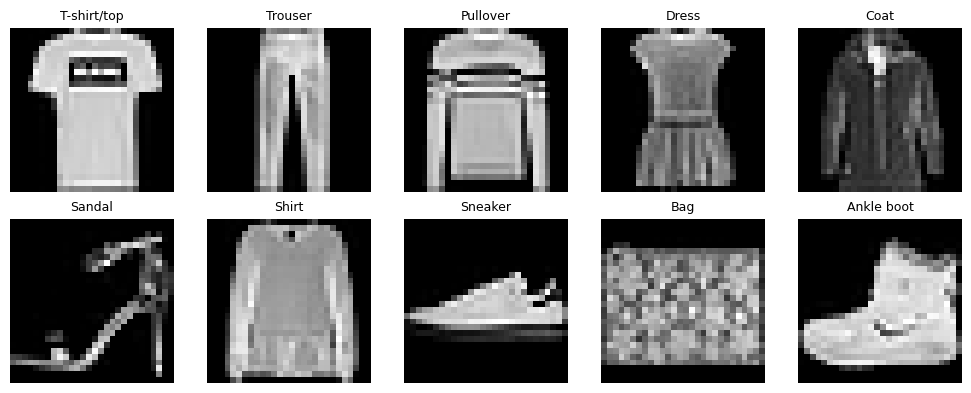

In [ ]:
DATA_DIR = pathlib.Path("/content/fashion-mnist"); DATA_DIR.mkdir(exist_ok=True)
BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
         "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
for f in FILES:
    if not (DATA_DIR / f).exists():
        urllib.request.urlretrieve(f"{BASE}/{f}", DATA_DIR / f)

def read_images(p):
    with gzip.open(p, "rb") as f:
        _, n, r, c = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), np.uint8).reshape(n, r, c)
def read_labels(p):
    with gzip.open(p, "rb") as f:
        _, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), np.uint8)

train_images, train_labels = read_images(DATA_DIR / FILES[0]), read_labels(DATA_DIR / FILES[1])
test_images, test_labels = read_images(DATA_DIR / FILES[2]), read_labels(DATA_DIR / FILES[3])
print("train:", train_images.shape, "| test:", test_images.shape)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for label, ax in enumerate(axes.flat):
    ax.imshow(train_images[np.flatnonzero(train_labels == label)[0]], cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
BATCH_SIZE, INPUT_DIM, NUM_CLASSES = 512, 784, 10
def prep(imgs): return (imgs.astype(np.float32) / 255.0).reshape(len(imgs), -1)

perm = np.random.default_rng(0).permutation(len(train_images))
x_train, y_train = prep(train_images[perm]), train_labels[perm].astype(np.int32)
x_test, y_test = prep(test_images), test_labels.astype(np.int32)

def make_fixed_batches(x, y, bs):
    n = (len(x) // bs) * bs
    return (jax.device_put(jnp.asarray(x[:n].reshape(-1, bs, x.shape[-1])), device),
            jax.device_put(jnp.asarray(y[:n].reshape(-1, bs)), device))

x_train_batches, y_train_batches = make_fixed_batches(x_train, y_train, BATCH_SIZE)
x_test_batches, y_test_batches = make_fixed_batches(x_test, y_test, BATCH_SIZE)
first_batch = (x_train_batches[0], y_train_batches[0])
print("train batches:", x_train_batches.shape, "| test batches:", x_test_batches.shape)

train batches: (117, 512, 784) | test batches: (19, 512, 784)


In [ ]:
HIDDEN1, HIDDEN2, LEARNING_RATE = 256, 128, 3e-3

def init_mlp_params(key):
    k1, k2, k3 = jax.random.split(key, 3)
    return {"w1": jax.random.normal(k1, (INPUT_DIM, HIDDEN1)) * math.sqrt(2 / INPUT_DIM), "b1": jnp.zeros(HIDDEN1),
            "w2": jax.random.normal(k2, (HIDDEN1, HIDDEN2)) * math.sqrt(2 / HIDDEN1),   "b2": jnp.zeros(HIDDEN2),
            "w3": jax.random.normal(k3, (HIDDEN2, NUM_CLASSES)) * math.sqrt(2 / HIDDEN2), "b3": jnp.zeros(NUM_CLASSES)}

def mlp(params, x, compute_dtype=jnp.float32):
    p = {k: v.astype(compute_dtype) for k, v in params.items()}
    x = jax.nn.gelu(x.astype(compute_dtype) @ p["w1"] + p["b1"])
    x = jax.nn.gelu(x @ p["w2"] + p["b2"])
    return (x @ p["w3"] + p["b3"]).astype(jnp.float32)

def cross_entropy_loss(params, batch, compute_dtype=jnp.float32):
    x, y = batch
    return optax.softmax_cross_entropy_with_integer_labels(mlp(params, x, compute_dtype), y).mean()

def loss_with_metrics(params, batch, compute_dtype=jnp.float32):
    x, y = batch; logits = mlp(params, x, compute_dtype)
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return loss, {"accuracy": jnp.mean(jnp.argmax(logits, -1) == y)}

params = jax.device_put(init_mlp_params(jax.random.key(1)), device)
print("Parameters:", f"{sum(v.size for v in params.values()):,}")
loss_value, grads = jax.value_and_grad(cross_entropy_loss)(params, first_batch)
for k in params: print(f"  {k}: param {params[k].shape} | grad {grads[k].shape}")
print("loss:", float(loss_value), "| gradient norm:", float(tree_l2_norm(grads)))

Parameters: 235,146
  b1: param (256,) | grad (256,)
  b2: param (128,) | grad (128,)
  b3: param (10,) | grad (10,)
  w1: param (784, 256) | grad (784, 256)
  w2: param (256, 128) | grad (256, 128)
  w3: param (128, 10) | grad (128, 10)
loss: 2.368513822555542 | gradient norm: 1.587838053703308


In [ ]:
def sgd_step(params, batch):
    loss, grads = jax.value_and_grad(cross_entropy_loss)(params, batch)
    return jax.tree.map(lambda p, g: p - LEARNING_RATE * g, params, grads), loss
sgd_step_jit = jax.jit(sgd_step)

def batch_at(step):
    i = step % x_train_batches.shape[0]
    return x_train_batches[i], y_train_batches[i]

def time_loop(step_fn, params, steps):
    t0 = time.perf_counter()
    for s in range(steps): params, loss = step_fn(params, batch_at(s))
    block_tree((params, loss)); return time.perf_counter() - t0

block_tree(sgd_step_jit(params, first_batch))
eager  = 20 * BATCH_SIZE / time_loop(sgd_step, params, 20)
jitted = 100 * BATCH_SIZE / time_loop(sgd_step_jit, params, 100)
print(f"Without jit: {eager:,.0f} examples/sec | With jit: {jitted:,.0f} examples/sec -> {jitted/eager:.0f}x faster")

Without jit: 5,050 examples/sec | With jit: 303,458 examples/sec -> 60x faster


Trained 400 steps in 1.7s -> 119,971 examples/sec
  step   0 | loss 1.9685 | accuracy 38.1%
  step 100 | loss 0.4875 | accuracy 82.0%
  step 200 | loss 0.3625 | accuracy 85.4%
  step 300 | loss 0.3280 | accuracy 88.3%
  step 399 | loss 0.2848 | accuracy 89.1%


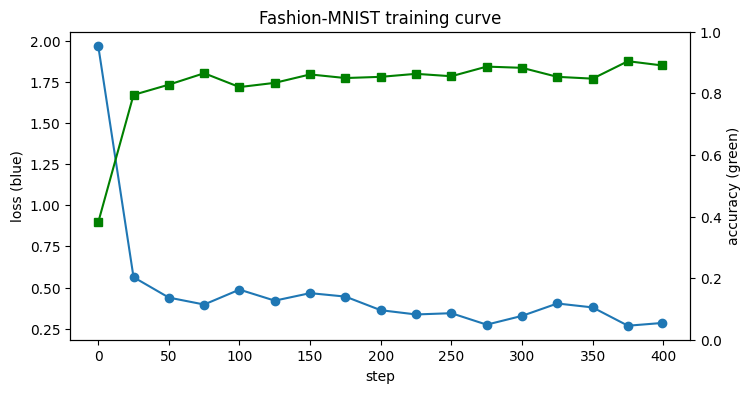

In [ ]:
optimizer = optax.adamw(learning_rate=LEARNING_RATE, weight_decay=1e-4)

@jax.jit
def train_step(params, opt_state, batch):
    (loss, m), grads = jax.value_and_grad(loss_with_metrics, has_aux=True)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, {"loss": loss, "accuracy": m["accuracy"]}

params_train = jax.device_put(init_mlp_params(jax.random.key(3)), device)
opt_state = optimizer.init(params_train)
params_train, opt_state, _ = train_step(params_train, opt_state, first_batch)   # warm-up

history, t0 = [], time.perf_counter()
for step in range(400):
    params_train, opt_state, m = train_step(params_train, opt_state, batch_at(step))
    if step % 25 == 0 or step == 399:
        history.append((step, float(m["loss"]), float(m["accuracy"])))
block_tree(params_train); elapsed = time.perf_counter() - t0

print(f"Trained 400 steps in {elapsed:.1f}s -> {400 * BATCH_SIZE / elapsed:,.0f} examples/sec")
for s, l, a in history[::4]: print(f"  step {s:3d} | loss {l:.4f} | accuracy {a*100:.1f}%")

steps, losses, accs = zip(*history)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(steps, losses, "o-"); ax1.set_xlabel("step"); ax1.set_ylabel("loss (blue)")
ax2 = ax1.twinx(); ax2.plot(steps, accs, "s-", color="green"); ax2.set_ylabel("accuracy (green)"); ax2.set_ylim(0, 1)
plt.title("Fashion-MNIST training curve"); plt.show()

TEST accuracy: 87.7% on 9,728 unseen images


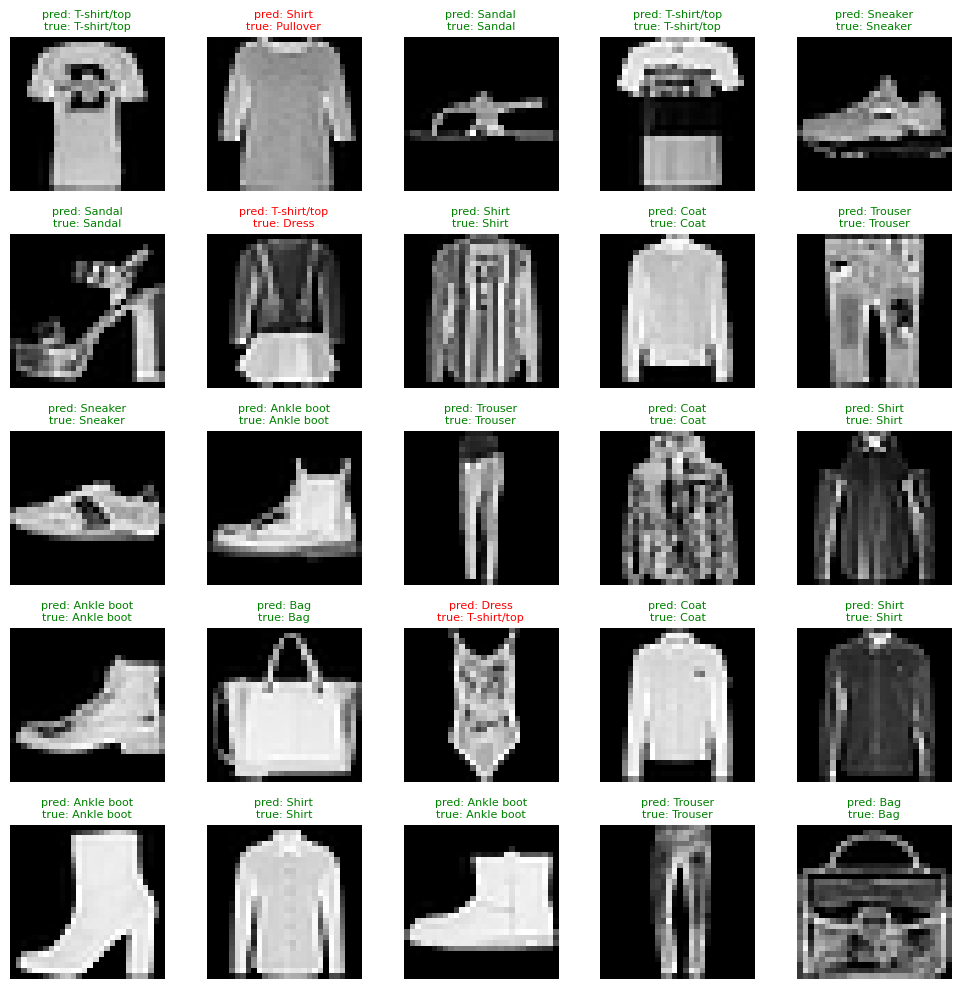

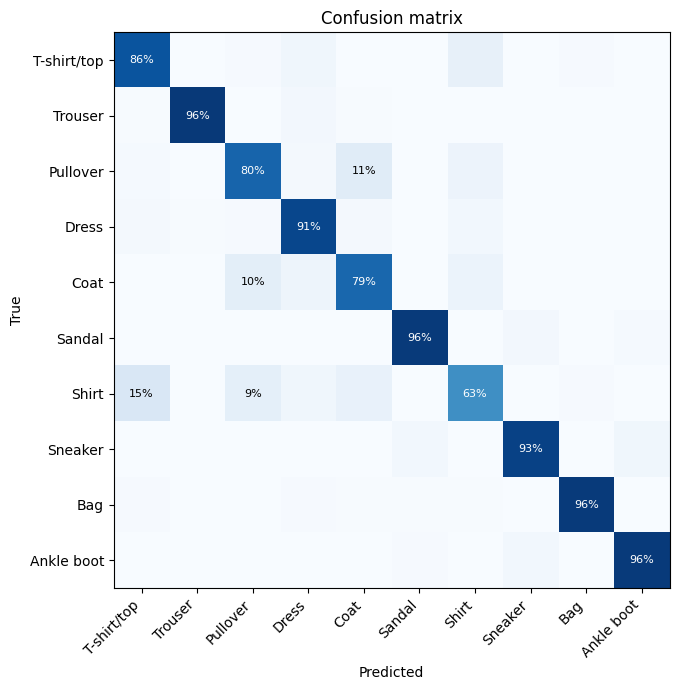

In [ ]:
@jax.jit
def evaluate(params):
    def one(x, y):
        loss, m = loss_with_metrics(params, (x, y)); return loss, m["accuracy"]
    l, a = jax.vmap(one)(x_test_batches, y_test_batches); return l.mean(), a.mean()

tl, ta = evaluate(params_train)
print(f"TEST accuracy: {float(ta)*100:.1f}% on {y_test_batches.size:,} unseen images")

@jax.jit
def predict(params, x): return jnp.argmax(mlp(params, x), -1)

idx = np.random.default_rng(7).choice(len(test_images), 25, replace=False)
pred = np.asarray(predict(params_train, jnp.asarray(prep(test_images[idx]))))
fig, axes = plt.subplots(5, 5, figsize=(10, 10))
for ax, img, t, p in zip(axes.flat, test_images[idx], test_labels[idx], pred):
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"pred: {CLASS_NAMES[p]}\ntrue: {CLASS_NAMES[t]}", fontsize=8,
                 color="green" if p == t else "red")
plt.tight_layout(); plt.show()

test_pred = np.asarray(jax.vmap(lambda x: predict(params_train, x))(x_test_batches)).reshape(-1)
test_true = np.asarray(y_test_batches).reshape(-1)
cm = np.zeros((10, 10), int); np.add.at(cm, (test_true, test_pred), 1)
cmp = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7)); ax.imshow(cmp, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix")
for i in range(10):
    for j in range(10):
        if cmp[i, j] >= 0.08 or i == j:
            ax.text(j, i, f"{cmp[i, j]*100:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if cmp[i, j] > 0.45 else "black")
plt.tight_layout(); plt.show()

In [ ]:
@partial(jax.jit, static_argnames=("compute_dtype",))
def train_step_mixed(params, opt_state, batch, compute_dtype=jnp.float32):
    (loss, m), grads = jax.value_and_grad(loss_with_metrics, has_aux=True)(params, batch, compute_dtype=compute_dtype)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, {"loss": loss, "accuracy": m["accuracy"]}

def time_dtype(dt, steps=100):
    p = jax.device_put(init_mlp_params(jax.random.key(10)), device); o = optimizer.init(p)
    p, o, m = train_step_mixed(p, o, first_batch, compute_dtype=dt); block_tree(p)
    t0 = time.perf_counter()
    for s in range(steps): p, o, m = train_step_mixed(p, o, batch_at(s), compute_dtype=dt)
    block_tree((p, m)); e = time.perf_counter() - t0
    print(f"{str(jnp.dtype(dt)):9s} | loss {float(m['loss']):.4f} | acc {float(m['accuracy'])*100:.1f}% | {steps * BATCH_SIZE / e:,.0f} examples/sec")

time_dtype(jnp.float32)
time_dtype(jnp.bfloat16)

float32   | loss 0.4835 | acc 83.2% | 36,376 examples/sec
bfloat16  | loss 0.4829 | acc 83.4% | 46,130 examples/sec


In [ ]:
import math, time
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
block_tree = jax.block_until_ready

BATCH, SEQ_LEN, NUM_HEADS, HEAD_DIM = 4, 128, 8, 64
k1, k2, k3 = jax.random.split(jax.random.key(0), 3)
shape = (BATCH, SEQ_LEN, NUM_HEADS, HEAD_DIM)
q, k, v = (jax.random.normal(kk, shape) for kk in (k1, k2, k3))
print("Q, K, V shape:", q.shape, "| layout (Batch, Time, Heads, HeadDim) | on", q.devices())

Q, K, V shape: (4, 128, 8, 64) | layout (Batch, Time, Heads, HeadDim) | on {CudaDevice(id=0)}


In [ ]:
def naive_attention(q, k, v):
    scale = 1.0 / math.sqrt(q.shape[-1])
    q_t, k_t, v_t = (jnp.transpose(a, (0, 2, 1, 3)) for a in (q, k, v))
    scores = jnp.matmul(q_t, jnp.transpose(k_t, (0, 1, 3, 2))) * scale
    weights = jax.nn.softmax(scores, axis=-1)
    return jnp.transpose(jnp.matmul(weights, v_t), (0, 2, 1, 3))

naive_out = block_tree(naive_attention(q, k, v))
sdpa_out = block_tree(jax.nn.dot_product_attention(q, k, v))
print("Naive output:", naive_out.shape, "| Built-in output:", sdpa_out.shape)
print("Max difference:", float(jnp.max(jnp.abs(naive_out - sdpa_out))),
      "| Same result?", bool(jnp.allclose(naive_out, sdpa_out, atol=1e-3)))

Naive output: (4, 128, 8, 64) | Built-in output: (4, 128, 8, 64)
Max difference: 0.0 | Same result? True


In [ ]:
q_bf16, k_bf16, v_bf16 = (a.astype(jnp.bfloat16) for a in (q, k, v))
HAS_CUDNN_SDPA = False
try:
    block_tree(jax.nn.dot_product_attention(q_bf16, k_bf16, v_bf16, implementation="cudnn"))
    HAS_CUDNN_SDPA = True
    print("✅ cuDNN fused attention works on this GPU")
except Exception as e:
    print("❌ cuDNN fused attention is not available here (T4 = compute capability 7.5, needs 8.0+)")
    print("   reason:", str(e).splitlines()[0][:150])

❌ cuDNN fused attention is not available here (T4 = compute capability 7.5, needs 8.0+)
   reason: INTERNAL: SDPA FP16/BF16 requires SM80 (Ampere) or newer architecture


In [ ]:
causal = block_tree(jax.nn.dot_product_attention(q, k, v, is_causal=True))
full = block_tree(jax.nn.dot_product_attention(q, k, v, is_causal=False))
print(f"First position difference: {float(jnp.max(jnp.abs(causal[:, 0] - full[:, 0]))):.4f}  -> large (can only see itself)")
print(f"Last position difference:  {float(jnp.max(jnp.abs(causal[:, -1] - full[:, -1]))):.2e}  -> ~0 (sees everything either way)")

First position difference: 3.5981  -> large (can only see itself)
Last position difference:  0.00e+00  -> ~0 (sees everything either way)


seq_len 64:
   ⚠️ built-in bf16 failed: UNIMPLEMENTED: Unsupported algorithm on the current device(s): ALG_DOT_BF16_BF16_F32
seq_len 128:
   ⚠️ built-in bf16 failed: UNIMPLEMENTED: Unsupported algorithm on the current device(s): ALG_DOT_BF16_BF16_F32
seq_len 256:
   ⚠️ built-in bf16 failed: UNIMPLEMENTED: Unsupported algorithm on the current device(s): ALG_DOT_BF16_BF16_F32
seq_len 512:
   ⚠️ built-in bf16 failed: UNIMPLEMENTED: Unsupported algorithm on the current device(s): ALG_DOT_BF16_BF16_F32
seq_len 1024:
   ⚠️ built-in bf16 failed: UNIMPLEMENTED: Unsupported algorithm on the current device(s): ALG_DOT_BF16_BF16_F32

seq_len | naive ms | built-in f32 ms | built-in bf16 ms
     64 |     0.24 |            0.27 |              nan
    128 |     0.35 |            0.37 |              nan
    256 |     0.68 |            0.67 |              nan
    512 |     1.89 |            1.95 |              nan
   1024 |     6.10 |            5.55 |              nan


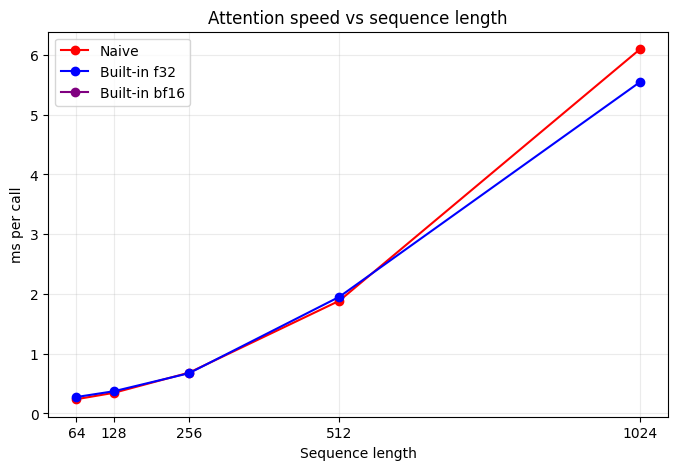

In [ ]:
def bench(fn, q, k, v, warmup=2, repeats=20):
    f = jax.jit(fn)
    for _ in range(warmup): block_tree(f(q, k, v))
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); block_tree(f(q, k, v)); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

def safe(name, fn, q, k, v):
    try:
        return bench(fn, q, k, v)
    except Exception as e:
        msg = [l for l in str(e).splitlines() if l.strip()]
        print(f"   ⚠️ {name} failed: {msg[0][:160] if msg else type(e).__name__}")
        return float("nan")

xla = lambda q, k, v: jax.nn.dot_product_attention(q, k, v, implementation="xla")
rows = []
for sl in [64, 128, 256, 512, 1024]:
    a, b, c = jax.random.split(jax.random.key(sl), 3)
    s = (BATCH, sl, NUM_HEADS, HEAD_DIM)
    qs, ks, vs = (jax.random.normal(kk, s) for kk in (a, b, c))
    qb, kb, vb = (x.astype(jnp.bfloat16) for x in (qs, ks, vs))
    print(f"seq_len {sl}:")
    rows.append((sl,
                 safe("naive", naive_attention, qs, ks, vs),
                 safe("built-in f32", xla, qs, ks, vs),
                 safe("built-in bf16", xla, qb, kb, vb)))

print("\nseq_len | naive ms | built-in f32 ms | built-in bf16 ms")
for r in rows: print(f"{r[0]:7d} | {r[1]:8.2f} | {r[2]:15.2f} | {r[3]:16.2f}")

sl = [r[0] for r in rows]
plt.figure(figsize=(8, 5))
for i, (lab, col) in enumerate([("Naive", "red"), ("Built-in f32", "blue"), ("Built-in bf16", "purple")], start=1):
    plt.plot(sl, [r[i] for r in rows], "o-", label=lab, color=col)
plt.xlabel("Sequence length"); plt.ylabel("ms per call"); plt.title("Attention speed vs sequence length")
plt.xticks(sl); plt.legend(); plt.grid(alpha=0.25); plt.show()

In [ ]:
print("batch | built-in f32 ms | ms per example")
for bs in [1, 2, 4, 8, 16]:
    a, b, c = jax.random.split(jax.random.key(bs + 100), 3)
    s = (bs, 256, NUM_HEADS, HEAD_DIM)
    qs, ks, vs = (jax.random.normal(kk, s) for kk in (a, b, c))
    t = safe("built-in f32", xla, qs, ks, vs)
    print(f"{bs:5d} | {t:15.2f} | {t / bs:14.3f}")

batch | built-in f32 ms | ms per example
    1 |            0.37 |          0.368
    2 |            0.50 |          0.248
    4 |            0.70 |          0.175
    8 |            1.12 |          0.140
   16 |            1.98 |          0.124


In [ ]:
r = jax.random.split(jax.random.key(42), 3)
q_m = jax.random.normal(r[0], (2, 64, 8, 64))
for name, n in {"MHA (8 KV heads)": 8, "GQA (2 KV heads)": 2, "MQA (1 KV head)": 1}.items():
    kk = jax.random.normal(r[1], (2, 64, n, 64)); vv = jax.random.normal(r[2], (2, 64, n, 64))
    out = block_tree(jax.nn.dot_product_attention(q_m, kk, vv))
    print(f"{name:17s} | K shape {kk.shape} | output {out.shape}")

MHA (8 KV heads)  | K shape (2, 64, 8, 64) | output (2, 64, 8, 64)
GQA (2 KV heads)  | K shape (2, 64, 2, 64) | output (2, 64, 8, 64)
MQA (1 KV head)   | K shape (2, 64, 1, 64) | output (2, 64, 8, 64)


In [ ]:
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=8"
os.environ["JAX_PLATFORMS"] = "cpu"

import gzip, struct, math, time, pathlib, urllib.request
from functools import partial
import numpy as np, jax, jax.numpy as jnp, optax
from jax.sharding import Mesh, PartitionSpec as P, NamedSharding

devices = jax.devices()
NUM_DEVICES = len(devices)
print("Devices:", devices)
print("Device count:", NUM_DEVICES, "(simulated on CPU)")

Devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3), CpuDevice(id=4), CpuDevice(id=5), CpuDevice(id=6), CpuDevice(id=7)]
Device count: 8 (simulated on CPU)


In [ ]:
DATA_DIR = pathlib.Path("/content/fashion-mnist"); DATA_DIR.mkdir(exist_ok=True)
BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion"
for f in ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"]:
    if not (DATA_DIR / f).exists(): urllib.request.urlretrieve(f"{BASE}/{f}", DATA_DIR / f)
with gzip.open(DATA_DIR / "train-images-idx3-ubyte.gz") as f:
    _, n, r, c = struct.unpack(">IIII", f.read(16)); imgs = np.frombuffer(f.read(), np.uint8).reshape(n, r * c)
with gzip.open(DATA_DIR / "train-labels-idx1-ubyte.gz") as f:
    f.read(8); labels = np.frombuffer(f.read(), np.uint8)
perm = np.random.default_rng(0).permutation(n)
x_all, y_all = imgs[perm].astype(np.float32) / 255.0, labels[perm].astype(np.int32)

INPUT_DIM, WIDTH, NUM_CLASSES, BLOCK_REPEATS, BLOCK_MIX, LR = 784, 256, 10, 8, 0.1, 3e-4
PER_DEVICE_BATCH = 128
GLOBAL_BATCH = PER_DEVICE_BATCH * NUM_DEVICES

def init_params(seed=1):
    rng = np.random.default_rng(seed)
    nrm = lambda s, sc: rng.standard_normal(s).astype(np.float32) * sc
    return {"w_in": nrm((INPUT_DIM, WIDTH), math.sqrt(2 / INPUT_DIM)), "b_in": np.zeros(WIDTH, np.float32),
            "w_block": nrm((WIDTH, WIDTH), math.sqrt(2 / WIDTH)),   "b_block": np.zeros(WIDTH, np.float32),
            "w_out": nrm((WIDTH, NUM_CLASSES), math.sqrt(2 / WIDTH)), "b_out": np.zeros(NUM_CLASSES, np.float32)}

def make_batches(bs, nb=8):
    k = bs * nb
    return x_all[:k].reshape(nb, bs, INPUT_DIM), y_all[:k].reshape(nb, bs)

def model(p, x):
    h = jax.nn.gelu(x @ p["w_in"] + p["b_in"])
    def block(h, _):
        z = jax.nn.gelu(h @ p["w_block"] + p["b_block"])
        return (1 - BLOCK_MIX) * h + BLOCK_MIX * z, None
    h, _ = jax.lax.scan(block, h, None, length=BLOCK_REPEATS)
    return h @ p["w_out"] + p["b_out"]

def loss_with_metrics(p, batch):
    x, y = batch; logits = model(p, x)
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return loss, {"accuracy": jnp.mean(jnp.argmax(logits, -1) == y)}

optimizer = optax.adamw(LR, weight_decay=1e-4)

@jax.jit
def train_step(p, opt_state, batch):
    (loss, m), g = jax.value_and_grad(loss_with_metrics, has_aux=True)(p, batch)
    updates, opt_state = optimizer.update(g, opt_state, p)
    return optax.apply_updates(p, updates), opt_state, {"loss": loss, "accuracy": m["accuracy"]}

def benchmark(step_fn, p, o, xb, yb, warmup=2, steps=10):
    for i in range(warmup): p, o, _ = step_fn(p, o, (xb[i % len(xb)], yb[i % len(yb)]))
    jax.block_until_ready(p); t0 = time.perf_counter()
    for i in range(steps): p, o, m = step_fn(p, o, (xb[i % len(xb)], yb[i % len(yb)]))
    jax.block_until_ready((p, m)); e = time.perf_counter() - t0
    return {"ex_s": steps * xb.shape[1] / e, "ms": 1000 * e / steps, "loss": float(m["loss"])}

print(f"{len(x_all):,} images | per-device batch {PER_DEVICE_BATCH} | global batch {GLOBAL_BATCH}")

60,000 images | per-device batch 128 | global batch 1024


In [ ]:
d0 = devices[0]
xb1, yb1 = (jax.device_put(a, d0) for a in make_batches(PER_DEVICE_BATCH))
p1 = jax.device_put(init_params(), d0)
r1 = benchmark(train_step, p1, optimizer.init(p1), xb1, yb1)
print(f"1 device: {r1['ex_s']:,.0f} examples/sec | {r1['ms']:.1f} ms/step | loss {r1['loss']:.3f}")

1 device: 8,921 examples/sec | 14.3 ms/step | loss 1.716


In [ ]:
mesh = Mesh(np.array(devices), ("data",))
all_data = NamedSharding(mesh, P(None, "data", None))
all_label = NamedSharding(mesh, P(None, "data"))
replicated = NamedSharding(mesh, P())

xs, ys = make_batches(GLOBAL_BATCH)
xs, ys = jax.device_put(xs, all_data), jax.device_put(ys, all_label)
pm = jax.device_put(init_params(), replicated)

print("Mesh:", mesh.shape, "| batches:", xs.shape)
print("\nOne batch -> SPLIT across 8 devices:")
jax.debug.visualize_array_sharding(xs[0])
print("\nWeight w_block -> COPIED to every device:")
jax.debug.visualize_array_sharding(pm["w_block"])

Mesh: OrderedDict({'data': 8}) | batches: (8, 1024, 784)

One batch -> SPLIT across 8 devices:


      CPU 0      
                 
      CPU 1      
                 
      CPU 2      
                 
      CPU 3      
                 
      CPU 4      
                 
      CPU 5      
                 
      CPU 6      
                 
      CPU 7      
                 


Weight w_block -> COPIED to every device:


                         
                         
                         
                         
                         
   CPU 0,1,2,3,4,5,6,7   
                         
                         
                         
                         
                         

In [ ]:
rm = benchmark(train_step, pm, optimizer.init(pm), xs, ys)
print(f"{NUM_DEVICES} devices: {rm['ex_s']:,.0f} examples/sec | {rm['ms']:.1f} ms/step | loss {rm['loss']:.3f}")
print(f"Throughput vs 1 device: {rm['ex_s'] / r1['ex_s']:.2f}x")

8 devices: 10,120 examples/sec | 101.2 ms/step | loss 1.642
Throughput vs 1 device: 1.13x


In [ ]:
@partial(jax.shard_map, mesh=mesh, in_specs=(P(), P("data", None), P("data")), out_specs=(P(), P(), P()))
def grads_shardmap(p, x, y):
    (loss, m), g = jax.value_and_grad(loss_with_metrics, has_aux=True)(p, (x, y))
    return jax.lax.pmean(g, "data"), jax.lax.pmean(loss, "data"), jax.lax.pmean(m["accuracy"], "data")

@jax.jit
def train_step_explicit(p, o, batch):
    g, loss, acc = grads_shardmap(p, *batch)
    updates, o = optimizer.update(g, o, p)
    return optax.apply_updates(p, updates), o, {"loss": loss, "accuracy": acc}

pe = jax.device_put(init_params(), replicated)
re = benchmark(train_step_explicit, pe, optimizer.init(pe), xs, ys)
print(f"Automatic (jit):    loss {rm['loss']:.4f} | {rm['ex_s']:,.0f} ex/s")
print(f"Explicit shard_map: loss {re['loss']:.4f} | {re['ex_s']:,.0f} ex/s")

Automatic (jit):    loss 1.6417 | 10,120 ex/s
Explicit shard_map: loss 1.6417 | 10,318 ex/s


In [ ]:
print("global batch | per device | examples/sec")
for bs in [256, 512, 1024, 2048]:
    xb, yb = make_batches(bs)
    xb, yb = jax.device_put(xb, all_data), jax.device_put(yb, all_label)
    pb = jax.device_put(init_params(), replicated)
    r = benchmark(train_step, pb, optimizer.init(pb), xb, yb)
    print(f"{bs:12d} | {bs // NUM_DEVICES:10d} | {r['ex_s']:,.0f}")

global batch | per device | examples/sec
         256 |         32 | 5,518
         512 |         64 | 8,224
        1024 |        128 | 9,737
        2048 |        256 | 12,171


In [ ]:
!pip install -q -U flax orbax-checkpoint

In [ ]:
!pip install -q flax orbax-checkpoint optax
import os, pathlib, time, urllib.request, shutil, warnings
warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt
import jax, jax.numpy as jnp, optax, flax
from flax import nnx
import orbax.checkpoint as ocp
block_tree = jax.block_until_ready
print("JAX", jax.__version__, "| Flax", flax.__version__, "| devices:", jax.devices())

JAX 0.11.1 | Flax 0.12.10 | devices: [CudaDevice(id=0)]


In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_FILE = pathlib.Path("/content/tinyshakespeare.txt")
if not DATA_FILE.exists(): urllib.request.urlretrieve(URL, DATA_FILE)
raw_text = DATA_FILE.read_text()

VOCAB_SIZE, SEQ_LEN, BATCH = 256, 256, 32
data = np.frombuffer(raw_text.encode("utf-8"), dtype=np.uint8).astype(np.int32)
num_seq = len(data) // SEQ_LEN
data = data[: num_seq * SEQ_LEN].reshape(num_seq, SEQ_LEN)
num_train = int(0.9 * num_seq)
train_data = data[:num_train][np.random.default_rng(0).permutation(num_train)]

def make_batches(d, bs):
    u = (len(d) // bs) * bs
    return d[:u].reshape(-1, bs, SEQ_LEN)

print(f"{len(raw_text):,} characters | {num_train:,} training sequences of {SEQ_LEN} letters")
print("\nSample:\n" + raw_text[:200])

1,115,394 characters | 3,921 training sequences of 256 letters

Sample:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


In [ ]:
D_MODEL, NUM_HEADS, FFN_DIM, NUM_LAYERS, MAX_SEQ_LEN, LR = 256, 4, 1024, 4, 256, 3e-4
ListCls = getattr(nnx, "List", list)

def causal_sdpa(query, key, value, **_):
    return jax.nn.dot_product_attention(query, key, value, is_causal=True)

class TransformerBlock(nnx.Module):
    def __init__(self, d_model, num_heads, ffn_dim, rngs):
        self.ln1 = nnx.LayerNorm(d_model, rngs=rngs)
        self.attn = nnx.MultiHeadAttention(num_heads=num_heads, in_features=d_model,
                                           decode=False, attention_fn=causal_sdpa, rngs=rngs)
        self.ln2 = nnx.LayerNorm(d_model, rngs=rngs)
        self.fc_up = nnx.Linear(d_model, ffn_dim, rngs=rngs)
        self.fc_down = nnx.Linear(ffn_dim, d_model, rngs=rngs)
    def __call__(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.fc_down(jax.nn.gelu(self.fc_up(self.ln2(x))))

class TinyTransformer(nnx.Module):
    def __init__(self, rngs):
        self.token_embed = nnx.Embed(VOCAB_SIZE, D_MODEL, rngs=rngs)
        self.pos_embed = nnx.Embed(MAX_SEQ_LEN, D_MODEL, rngs=rngs)
        self.blocks = ListCls([TransformerBlock(D_MODEL, NUM_HEADS, FFN_DIM, rngs) for _ in range(NUM_LAYERS)])
        self.final_norm = nnx.LayerNorm(D_MODEL, rngs=rngs)
        self.lm_head = nnx.Linear(D_MODEL, VOCAB_SIZE, use_bias=False, rngs=rngs)
    def __call__(self, tokens):
        x = self.token_embed(tokens) + self.pos_embed(jnp.arange(tokens.shape[1]))
        for block in self.blocks: x = block(x)
        return self.lm_head(self.final_norm(x))

test_model = TinyTransformer(rngs=nnx.Rngs(0))
n_params = sum(x.size for x in jax.tree.leaves(nnx.state(test_model, nnx.Param)))
print(f"TinyTransformer: {NUM_LAYERS} layers, {NUM_HEADS} heads, {n_params:,} parameters")
print("Test: input (1, 16) -> logits", test_model(jnp.zeros((1, 16), jnp.int32)).shape)

TinyTransformer: 4 layers, 4 heads, 3,356,160 parameters
Test: input (1, 16) -> logits (1, 16, 256)


In [ ]:
@nnx.jit
def train_step(model, optimizer, tokens):
    def loss_fn(model):
        logits = model(tokens)
        pred = logits[:, :-1].reshape(-1, VOCAB_SIZE)
        target = tokens[:, 1:].reshape(-1)
        return optax.softmax_cross_entropy_with_integer_labels(pred, target).mean()
    loss, grads = nnx.value_and_grad(loss_fn)(model)
    optimizer.update(model, grads)
    return {"loss": loss, "perplexity": jnp.exp(loss)}

def train_loop(model, optimizer, batches, steps, log_every=100):
    block_tree(train_step(model, optimizer, batches[0]))          # warm-up compile
    history, start = [], time.perf_counter()
    for step in range(steps):
        m = train_step(model, optimizer, batches[step % batches.shape[0]])
        if step % log_every == 0 or step == steps - 1:
            m = block_tree(m)
            history.append((step, float(m["loss"]), float(m["perplexity"])))
    block_tree(m); elapsed = time.perf_counter() - start
    return history, steps * batches.shape[1] * (SEQ_LEN - 1) / elapsed
print("Training functions ready.")

Training functions ready.


Trained 1000 steps at 107,304 tokens/sec

  step    0 | loss 4.631 | perplexity  102.7
  step  100 | loss 2.544 | perplexity   12.7
  step  200 | loss 2.481 | perplexity   12.0
  step  300 | loss 2.438 | perplexity   11.5
  step  400 | loss 2.313 | perplexity   10.1
  step  500 | loss 2.113 | perplexity    8.3
  step  600 | loss 2.017 | perplexity    7.5
  step  700 | loss 1.849 | perplexity    6.4
  step  800 | loss 1.806 | perplexity    6.1
  step  900 | loss 1.687 | perplexity    5.4
  step  999 | loss 1.661 | perplexity    5.3


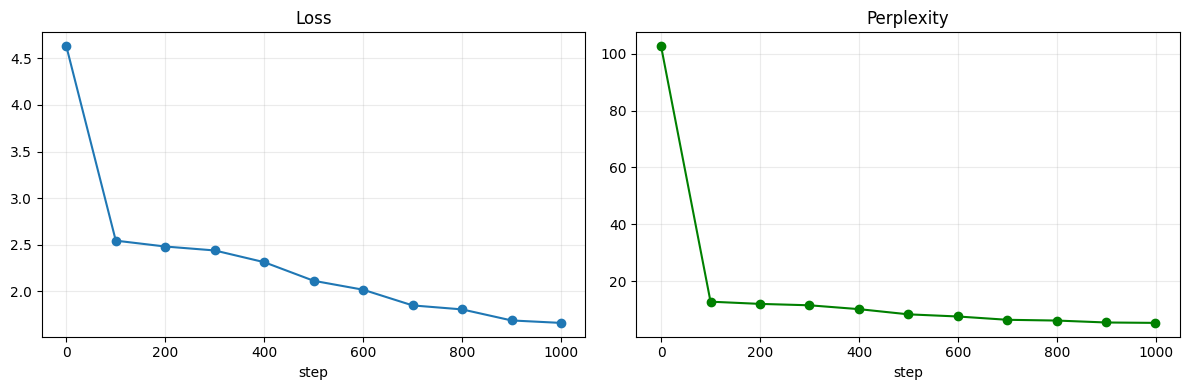

In [ ]:
batches = jax.device_put(make_batches(train_data, BATCH), jax.devices()[0])
model = TinyTransformer(rngs=nnx.Rngs(1))
optimizer = nnx.Optimizer(model, optax.adamw(LR, weight_decay=1e-4), wrt=nnx.Param)

STEPS = 1000
history, tps = train_loop(model, optimizer, batches, STEPS)
print(f"Trained {STEPS} steps at {tps:,.0f} tokens/sec\n")
for s, l, p in history: print(f"  step {s:4d} | loss {l:.3f} | perplexity {p:6.1f}")

steps_, losses, perps = zip(*history)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(steps_, losses, "o-"); a1.set_title("Loss"); a1.set_xlabel("step"); a1.grid(alpha=0.25)
a2.plot(steps_, perps, "o-", color="green"); a2.set_title("Perplexity"); a2.set_xlabel("step"); a2.grid(alpha=0.25)
plt.tight_layout(); plt.show()

In [ ]:
ckpt_dir = pathlib.Path("/tmp/jax-course/l7-checkpoints")
if (ckpt_dir / "trained").exists(): shutil.rmtree(ckpt_dir / "trained")
ckpt_dir.mkdir(parents=True, exist_ok=True)

model_params = nnx.state(model, nnx.Param)
checkpointer = ocp.StandardCheckpointer()
checkpointer.save(ckpt_dir / "trained", model_params)
if hasattr(checkpointer, "wait_until_finished"): checkpointer.wait_until_finished()

abstract_params = jax.tree.map(lambda x: jax.ShapeDtypeStruct(x.shape, x.dtype), model_params)
model_restored = TinyTransformer(rngs=nnx.Rngs(99))
nnx.update(model_restored, checkpointer.restore(ckpt_dir / "trained", abstract_params))

t = jnp.zeros((1, 16), jnp.int32)
diff = float(jnp.max(jnp.abs(model(t) - model_restored(t))))
print("Saved to:", ckpt_dir / "trained")
print(f"Max difference original vs restored: {diff:.2e} ->", "✅ match" if diff < 1e-5 else "❌")

Saved to: /tmp/jax-course/l7-checkpoints/trained
Max difference original vs restored: 0.00e+00 -> ✅ match


In [ ]:
@jax.jit
def get_logits(graphdef, state, tokens):
    return nnx.merge(graphdef, state)(tokens)

def generate(model, prompt, max_new_tokens=300, temperature=0.8):
    graphdef, state = nnx.split(model)
    tokens = list(prompt.encode("utf-8")); key = jax.random.key(42)
    for _ in range(max_new_tokens):
        ctx = tokens[-MAX_SEQ_LEN:]
        padded = jnp.array([ctx + [0] * (MAX_SEQ_LEN - len(ctx))], dtype=jnp.int32)
        logit = get_logits(graphdef, state, padded)[0, len(ctx) - 1]
        key, sub = jax.random.split(key)
        tokens.append(int(jax.random.categorical(sub, logit / temperature)))
    return bytes(tokens).decode("utf-8", errors="replace")

print("=== ROMEO: ===\n" + generate(model_restored, "ROMEO:"))
print("\n=== To be, or not ===\n" + generate(model_restored, "To be, or not", temperature=0.6))

=== ROMEO: ===
ROMEO:
I am the as do mirn of mor live the him,
To cound this hand course a like him sto the feor
Thy lay late frien live a him them.

LEONTES:
Your gentle: I my god man; he in and I
He have how be widh thee worst show of the disend,
Troy so thou doom blies apoute iorin youres arethin
se ove this reveve a

=== To be, or not ===
To be, or not give the prount trance,
And you the have to my love in him to seems.
The have stand grience it like a mousing live,
And see to shem the the pearling to me to to me.

BUCKINGHAM:
O the down a with thee words of concetimed
Tell is on him to my seap t tare seeeemin.
Orige of tretigs of thires oure the


In [ ]:
import pathlib, time, os, shutil
ckpt_dir = pathlib.Path("/tmp/jax-course/l7-checkpoints")
assert (ckpt_dir / "trained").exists(), "No checkpoint - run Lab 7 Box 6 first"

serve_model = TinyTransformer(rngs=nnx.Rngs(0))
abstract = jax.tree.map(lambda x: jax.ShapeDtypeStruct(x.shape, x.dtype), nnx.state(serve_model, nnx.Param))
restored = jax.device_put(ocp.StandardCheckpointer().restore(ckpt_dir / "trained", abstract), jax.devices()[0])
nnx.update(serve_model, restored)
print("✅ Checkpoint loaded:", ckpt_dir / "trained")
print(f"Parameters: {sum(x.size for x in jax.tree.leaves(restored)):,}")

✅ Checkpoint loaded: /tmp/jax-course/l7-checkpoints/trained
Parameters: 3,356,160


In [ ]:
graphdef, model_state = nnx.split(serve_model)

@jax.jit
def predict_jit(tokens): return nnx.merge(graphdef, model_state)(tokens)

dummy = jnp.zeros((1, MAX_SEQ_LEN), jnp.int32)
t0 = time.perf_counter(); logits = block_tree(predict_jit(dummy)); first_ms = (time.perf_counter() - t0) * 1000
ts = []
for _ in range(100):
    t0 = time.perf_counter(); logits = block_tree(predict_jit(dummy)); ts.append((time.perf_counter() - t0) * 1000)
avg_ms = np.mean(ts)
print(f"First call (compile + run): {first_ms:,.1f} ms")
print(f"Next 100 calls (average):   {avg_ms:.2f} ms  -> {first_ms / avg_ms:.0f}x faster")
print("Output shape:", logits.shape)

First call (compile + run): 1,658.1 ms
Next 100 calls (average):   2.71 ms  -> 611x faster
Output shape: (1, 256, 256)


In [ ]:
def predict_closed(tokens): return nnx.merge(graphdef, model_state)(tokens)

lowered = jax.jit(predict_closed).lower(jax.ShapeDtypeStruct((1, MAX_SEQ_LEN), jnp.int32))
compiled = lowered.compile()

t0 = time.perf_counter(); logits_aot = block_tree(compiled(dummy)); aot_first = (time.perf_counter() - t0) * 1000
ts = []
for _ in range(100):
    t0 = time.perf_counter(); block_tree(compiled(dummy)); ts.append((time.perf_counter() - t0) * 1000)
print(f"AOT first call: {aot_first:.2f} ms  (vs JIT first call {first_ms:,.1f} ms)")
print(f"AOT average: {np.mean(ts):.2f} ms | Max |JIT - AOT|: {float(jnp.max(jnp.abs(logits - logits_aot))):.2e}")

hlo = lowered.as_text()
pathlib.Path("/tmp/jax-course").mkdir(parents=True, exist_ok=True)
pathlib.Path("/tmp/jax-course/l8-stablehlo.mlir").write_text(hlo)
lines = hlo.splitlines()
print(f"\nStableHLO program: {len(lines):,} lines. First 15:")
print("\n".join(l[:150] for l in lines[:15]))

AOT first call: 11.71 ms  (vs JIT first call 1,658.1 ms)
AOT average: 1.94 ms | Max |JIT - AOT|: 0.00e+00

StableHLO program: 752 lines. First 15:
module @jit_predict_closed attributes {mhlo.num_partitions = 1 : i32, mhlo.num_replicas = 1 : i32} {
  func.func public @main(%arg0: tensor<1x256xi32>) -> (tensor<1x256x256xf32> {jax.result_info = "result"}) {
    %cst = stablehlo.constant dense<"0x0C2D083DA51739BDFF41683DDD5073BDF5FCF7BDCC1FB63DB131023DFFDC8CBC6EB1083D46A6A1BC7E15803DCD3A1BBD521651BD93D5D33
    %cst_0 = stablehlo.constant dense<"0x22CBECBC920C46BC8FBA93BD1B48A0BDA3DF9C3D94D0933CDC20D9BD9212A8BD9D8F8FBB613EB13D830EA53C3235253E3577C23D2E586
    %cst_1 = stablehlo.constant dense<"0x58D07B3F93B9723FD5847D3F42097A3FEAA67C3FDD3B7F3F2F277B3FBF2A783FC255733F80D77A3FC1387A3F3EE7783F8BC47D3FE21A7
    %cst_2 = stablehlo.constant dense<"0x2810C0BB93BC26BA5F20D03927C5A73B9C55883BDEB293BBEB711E3B438DDFBB132EB23A844C45BC03B395BAD636F23AE6B244BB71A3B
    %cst_3 = stablehlo.constant dense<"

In [ ]:
print("batch | latency ms | tokens/sec")
for bs in [1, 4, 16, 64]:
    c = jax.jit(predict_closed).lower(jax.ShapeDtypeStruct((bs, MAX_SEQ_LEN), jnp.int32)).compile()
    x = jnp.zeros((bs, MAX_SEQ_LEN), jnp.int32); block_tree(c(x))
    ts = []
    for _ in range(50):
        t0 = time.perf_counter(); block_tree(c(x)); ts.append(time.perf_counter() - t0)
    m = np.mean(ts)
    print(f"{bs:5d} | {m * 1000:10.2f} | {bs * MAX_SEQ_LEN / m:,.0f}")

batch | latency ms | tokens/sec
    1 |       1.97 | 129,741
    4 |       5.01 | 204,589
   16 |      11.48 | 356,896
   64 |      45.39 | 360,923


In [ ]:
from jax import export

exported = export.export(jax.jit(predict_closed))(jax.ShapeDtypeStruct((1, MAX_SEQ_LEN), jnp.int32))
blob = exported.serialize()
export_dir = pathlib.Path("/tmp/jax-course/exports"); export_dir.mkdir(parents=True, exist_ok=True)
export_file = export_dir / "tiny_transformer_jax_export.bin"
export_file.write_bytes(blob)
print("Platforms:", exported.platforms, "| input:", exported.in_avals, "| output:", exported.out_avals)
print(f"Saved {len(blob) / 1024:,.0f} KB to {export_file}")

rehydrated = export.deserialize(bytearray(export_file.read_bytes()))
out = block_tree(rehydrated.call(dummy))
print("✅ Loaded from file and ran WITHOUT the model code | output:", out.shape,
      f"| max diff vs AOT: {float(jnp.max(jnp.abs(out - logits_aot))):.2e}")

Platforms: ('cuda',) | input: (ShapedArray(int32[1,256]),) | output: (ShapedArray(float32[1,256,256]),)
Saved 13,125 KB to /tmp/jax-course/exports/tiny_transformer_jax_export.bin
✅ Loaded from file and ran WITHOUT the model code | output: (1, 256, 256) | max diff vs AOT: 0.00e+00
